# Archives CityBikes : historique sur 5 ans

Ce notebook prépare et lance le téléchargement des **archives mensuelles officielles de CityBikes** pour Paris (`velib`), Lyon (`velov`) et Lille (`vlille`), sur les 5 dernières années jusqu'en 2026. Il complète la collecte en direct (toutes les 5 minutes), qui ne remonte que jusqu'à son démarrage.

**Source :** [data.citybik.es](https://data.citybik.es), un fichier Parquet par réseau et par mois (`AAAAMM-reseau-stats.parquet`) : historique des changements d'état des stations.

**Licence :** ODbL 1.0. Mention obligatoire : « Bike-share data by CityBikes contributors and available from https://data.citybik.es ». Le service est expérimental et sans garantie ; les conditions des opérateurs peuvent aussi s'appliquer.

**Limite à connaître :** l'archive commence en **novembre 2024**. Les années 2022 et 2023 n'existent pas, elles sont signalées et non inventées. Le notebook ne télécharge rien tant que `TELECHARGER` vaut `False`.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "config" / "cities.yml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from scripts.citybikes_archive import (
    ATTRIBUTION, build_plan, build_session, configured_networks, default_years,
    download_one, human, parquet_info, publish,
)

ANNEE_FIN = 2026
ANNEES = default_years(ANNEE_FIN, 5)          # 2022 à 2026
RESEAUX = configured_networks()               # velib, velov, vlille (config/cities.yml)
DOSSIER = PROJECT_ROOT / "data" / "citybikes-archive"
TELECHARGER = False        # True : télécharge les fichiers du plan (environ 950 Mo pour 2022 à 2026)
PUBLIER_R2 = False        # True : copie aussi les fichiers dans le bucket Bronze (citybikes-archive/)
print("Années :", ANNEES, "| réseaux :", RESEAUX, "| dossier :", DOSSIER.relative_to(PROJECT_ROOT).as_posix())

Années : [2022, 2023, 2024, 2025, 2026] | réseaux : ['velib', 'velov', 'vlille'] | dossier : data/citybikes-archive


## 1. Plan : ce que l'archive contient réellement

Le plan interroge seulement la liste des fichiers du serveur (quelques kilo-octets) : aucun fichier de données n'est téléchargé.

In [2]:
session = build_session()
plan = build_plan(session, ANNEES, RESEAUX)
fichiers = pd.DataFrame(plan["files"])

print(f"Années absentes de l'archive : {plan['missing_years'] or 'aucune'}")
print(f"{len(fichiers)} fichiers, {human(plan['total_bytes'])} au total")
resume = fichiers.groupby("network").agg(
    fichiers=("name", "size"), premier=("name", lambda s: s.min()[:6]), dernier=("name", lambda s: s.max()[:6]),
    taille_mo=("size", lambda s: round(s.sum() / 1e6)),
)
resume["mois_manquants"] = [", ".join(plan["gaps"][n]) or "aucun" for n in resume.index]
display(resume)

Années absentes de l'archive : [2022, 2023]
61 fichiers, 946 Mo au total


,fichiers,premier,dernier,taille_mo,mois_manquants
network,,,,,
velib,19,202411,202609,620,"202604, 202605, 202606, 202607"
velov,21,202411,202609,259,"202607, 202608"
vlille,21,202411,202609,66,"202606, 202607"


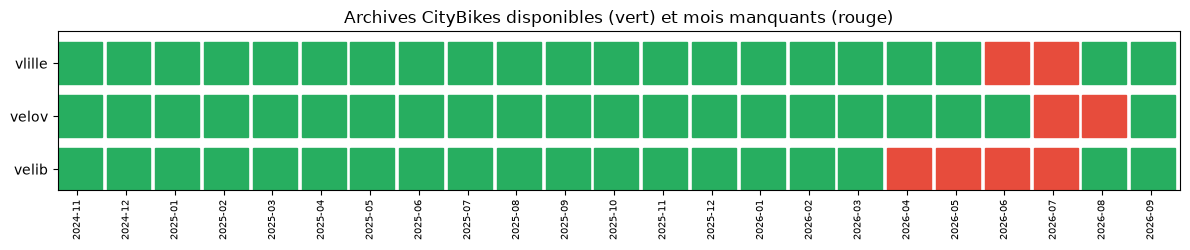

In [3]:
# Couverture mensuelle : un carré par réseau et par mois disponible
mois = sorted({(f["year"], f["month"]) for f in plan["files"]})
if mois:
    tous = [(y, m) for y in range(mois[0][0], mois[-1][0] + 1) for m in range(1, 13)
            if mois[0] <= (y, m) <= mois[-1]]
    dispo = {(f["network"], f["year"], f["month"]) for f in plan["files"]}
    fig, ax = plt.subplots(figsize=(12, 2.6))
    for i, reseau in enumerate(RESEAUX):
        for j, (y, m) in enumerate(tous):
            ax.add_patch(plt.Rectangle((j, i), 0.9, 0.8, color="#27ae60" if (reseau, y, m) in dispo else "#e74c3c"))
    ax.set_xlim(0, len(tous)); ax.set_ylim(0, len(RESEAUX))
    ax.set_yticks([i + 0.4 for i in range(len(RESEAUX))]); ax.set_yticklabels(RESEAUX)
    ax.set_xticks([j + 0.4 for j in range(len(tous))]); ax.set_xticklabels([f"{y}-{m:02d}" for y, m in tous], rotation=90, fontsize=7)
    ax.set_title("Archives CityBikes disponibles (vert) et mois manquants (rouge)")
    plt.tight_layout(); plt.show()

## 2. Téléchargement

Chaque fichier est téléchargé dans un fichier `.part`, comparé à la taille annoncée, vérifié comme Parquet lisible, puis renommé. Un fichier déjà complet n'est pas retéléchargé : on peut relancer sans risque. Le serveur est sollicité avec 2 téléchargements simultanés au plus, et un `HTTP 429` est respecté (attente demandée par le serveur).

En ligne de commande, le même travail s'écrit :

```bash
uv run python scripts/citybikes_archive.py --dry-run     # plan seulement
uv run python scripts/citybikes_archive.py               # télécharge dans data/citybikes-archive/
```

In [4]:
from concurrent.futures import ThreadPoolExecutor
import json

if not TELECHARGER:
    print("Téléchargement désactivé (TELECHARGER = False). Rien n'a été téléchargé.")
    print(f"Pour lancer : {len(plan['files'])} fichiers, {human(plan['total_bytes'])}, passer TELECHARGER à True.")
    resultats = []
else:
    DOSSIER.mkdir(parents=True, exist_ok=True)
    (DOSSIER / "ATTRIBUTION.txt").write_text(ATTRIBUTION + "\n", encoding="utf-8")
    with ThreadPoolExecutor(max_workers=2) as pool:
        resultats = list(pool.map(lambda e: download_one(session, DOSSIER, e), plan["files"]))
    (DOSSIER / "manifest.json").write_text(json.dumps({"files": resultats}, indent=2), encoding="utf-8")
    bilan = pd.DataFrame(resultats)
    print(bilan["status"].value_counts().to_dict(), "| lignes :", f"{int(bilan.get('rows', pd.Series(dtype=float)).sum()):,}")
    if PUBLIER_R2:
        print("Fichiers publiés dans Bronze :", publish(DOSSIER, resultats))

Téléchargement désactivé (TELECHARGER = False). Rien n'a été téléchargé.
Pour lancer : 61 fichiers, 946 Mo, passer TELECHARGER à True.


## 3. Inspection du schéma

Les colonnes exactes de ces fichiers ne sont pas documentées dans la page de l'archive : on les lit dans les métadonnées Parquet avant tout traitement. Cette cellule ne fait rien tant qu'aucun fichier n'est téléchargé.

In [5]:
fichiers_locaux = sorted(DOSSIER.glob("*/*.parquet")) if DOSSIER.exists() else []
if not fichiers_locaux:
    print("Aucun fichier téléchargé : le schéma sera affiché après le téléchargement.")
else:
    info = parquet_info(fichiers_locaux[0])
    print(f"{fichiers_locaux[0].name} : {info['rows']:,} lignes")
    display(pd.read_parquet(fichiers_locaux[0]).head())
    display(pd.read_parquet(fichiers_locaux[0]).dtypes.rename("type").to_frame())

Aucun fichier téléchargé : le schéma sera affiché après le téléchargement.


## 4. Suite prévue

1. Lire le schéma réel (section 3) et le documenter ici.
2. Transformer les changements d'état en **séries horaires par station**, avec les mêmes colonnes que le Silver CityBikes en direct (`bikes_available`, `free_slots`, heure UTC).
3. Calculer le Gold historique (taux de rupture, saturation, activité par station, profil par heure du jour) et le relier à la météo Open-Meteo de la même période.
4. Relancer le notebook 04 sur cet historique : pics journaliers, stations critiques et corrélations vélos et météo deviennent calculables.
5. Conserver la mention de la licence ODbL dans tout document de rendu.